# Rotation driven by GRACE: plots

Plots of the runs made by `grace_rotation_run.py`, which drive the dynamic rotation solver with the monthly GRACE direct load
(land $L$, plus the direct ocean load $D$ for the ocean forcings). The **dynamic** pole is the time-stepped solution, started in
equilibrium in April 2002. The **static** pole is the AA24 equilibrium with the load of each month. The pole is $\boldsymbol\omega/\Omega$ in mas,
with $\omega_1$ towards 0°E and $\omega_2$ towards 90°E. Grey bands mark gaps in the GRACE record, which the cubic spline bridges.
The runs have no relative angular momentum $\mathbf h$, so this is the mass-driven pole only.

Animations are in the `animation_grace_*.ipynb` notebooks.

In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from matplotlib.collections import LineCollection

# solver_dynamic and examples_dynamic_helper live one directory up, in new-code/
sys.path.append("..")

import solver_dynamic as sd
import examples_dynamic_helper as eh
import grace_data_helper as gh
import grace_plot_helper as ph

/space/dah94/rotation/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#=======================================================================
# Parameters
#=======================================================================

# The run to plot (see grace_rotation_run.py): forcing, degree and quality factor
forcing = "land-ocean"
lmax = 64
quality_factor = "100"

# Labels of the three forcings
forcing_labels = {
    "land": "land $L$",
    "land-ocean": "land and direct ocean $L + D$",
    "land-ocean-nogad": "$L + D$ without GAD",
}

In [3]:
#=======================================================================
# Earth model and the runs of all three forcings
#=======================================================================

state = sd.make_state(lmax)
model = state.model
constants = sd.rotation_constants(model)

runs = {name: gh.load_run(name, lmax, quality_factor) for name in gh.FORCINGS}
run = runs[forcing]

# The pole at the months, and on the full step grid
years = ph.years_from_days(run["month_days"])
step_years = ph.years_from_days(run["t_days"])
dynamic_mas = sd.omega_to_mas(run["dynamic_omega"], constants)
static_mas = sd.omega_to_mas(run["static_omega"], constants)
step_mas = run["pole_mas"]
gaps = ph.gap_spans(run["month_days"])
print(f"{len(years)} months, {run['dates'][0]} to {run['dates'][-1]}; {len(step_years) - 1} time steps")
print(f"{len(gaps)} gaps longer than 45 days; the longest from {max(gaps, key=lambda g: g[1] - g[0])[0]:.2f} "
      f"to {max(gaps, key=lambda g: g[1] - g[0])[1]:.2f}")

259 months, 2002-04-17 to 2026-07-16; 1069 time steps
19 gaps longer than 45 days; the longest from 2017.44 to 2018.45


## 1. Pole position against time

Solid lines are the dynamic pole, dashed lines the static pole, for the chosen forcing.

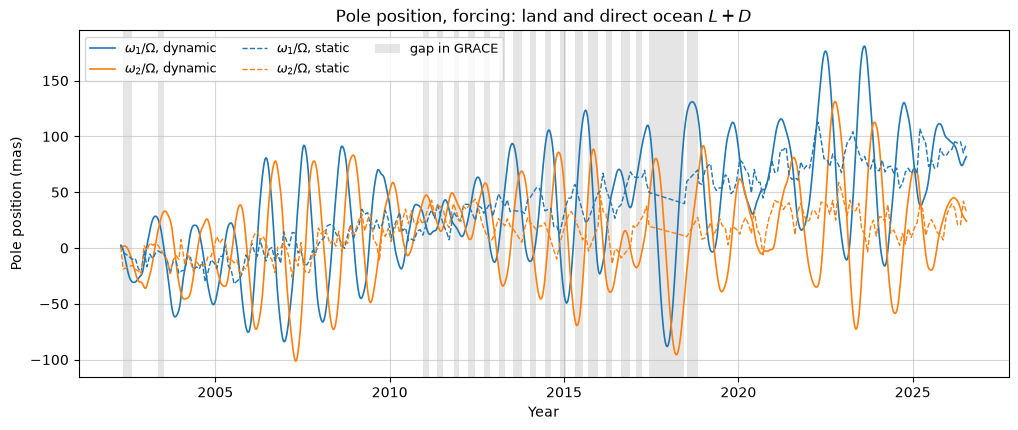

In [4]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(step_years, step_mas[:, 0], color="tab:blue", lw=1.2, label=r"$\omega_1/\Omega$, dynamic")
ax.plot(step_years, step_mas[:, 1], color="tab:orange", lw=1.2, label=r"$\omega_2/\Omega$, dynamic")
ax.plot(years, static_mas[:, 0], "--", color="tab:blue", lw=1, label=r"$\omega_1/\Omega$, static")
ax.plot(years, static_mas[:, 1], "--", color="tab:orange", lw=1, label=r"$\omega_2/\Omega$, static")
for i, (start, end) in enumerate(gaps):
    ax.axvspan(start, end, color="grey", alpha=0.2, lw=0, label="gap in GRACE" if i == 0 else None)
ax.set_xlabel("Year")
ax.set_ylabel("Pole position (mas)")
ax.set_title(f"Pole position, forcing: {forcing_labels[forcing]}")
ax.legend(ncol=3, fontsize=9)
ax.grid(True, alpha=0.5)
plt.show()

## 2. Pole locus

Left: the dynamic pole path, coloured by time, and the static path. Right: their difference, dynamic minus static. This is the free
(Chandler) wobble excited by the changing load, with the forced response removed to leading order.

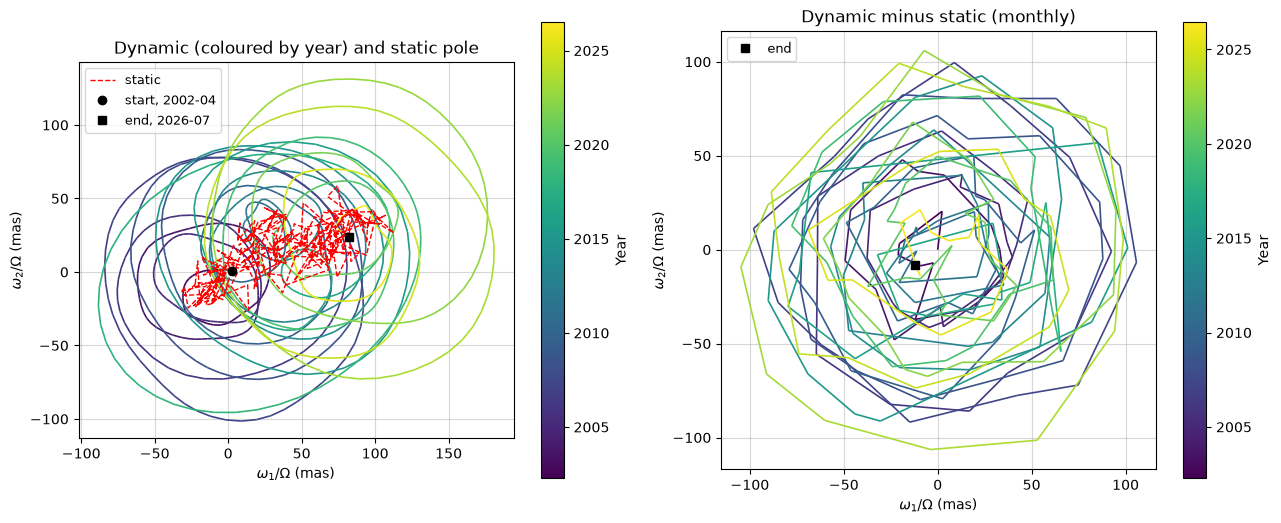

In [5]:
difference_mas = dynamic_mas - static_mas

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

# --- Dynamic and static paths ---
points = step_mas.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)
lines = LineCollection(segments, cmap="viridis", array=step_years[:-1], lw=1.2)
axes[0].add_collection(lines)
axes[0].plot(static_mas[:, 0], static_mas[:, 1], "r--", lw=1, label="static")
axes[0].plot(*step_mas[0], "ko", label=f"start, {str(run['dates'][0])[:7]}")
axes[0].plot(*step_mas[-1], "ks", label=f"end, {str(run['dates'][-1])[:7]}")
axes[0].autoscale()
axes[0].set_title("Dynamic (coloured by year) and static pole")
fig.colorbar(lines, ax=axes[0], label="Year", shrink=0.8)

# --- Dynamic minus static ---
points = difference_mas.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)
lines = LineCollection(segments, cmap="viridis", array=years[:-1], lw=1.2)
axes[1].add_collection(lines)
axes[1].plot(*difference_mas[-1], "ks", label="end")
axes[1].autoscale()
axes[1].set_title("Dynamic minus static (monthly)")
fig.colorbar(lines, ax=axes[1], label="Year", shrink=0.8)

for ax in axes:
    ax.set_xlabel(r"$\omega_1/\Omega$ (mas)")
    ax.set_ylabel(r"$\omega_2/\Omega$ (mas)")
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.5)
    ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

## 3. The free wobble: dynamic minus static

The components of the difference and its amplitude. The amplitude grows when the load's excitation near the Chandler frequency happens to be in phase
with the wobble, and decays slowly otherwise ($Q=100$).

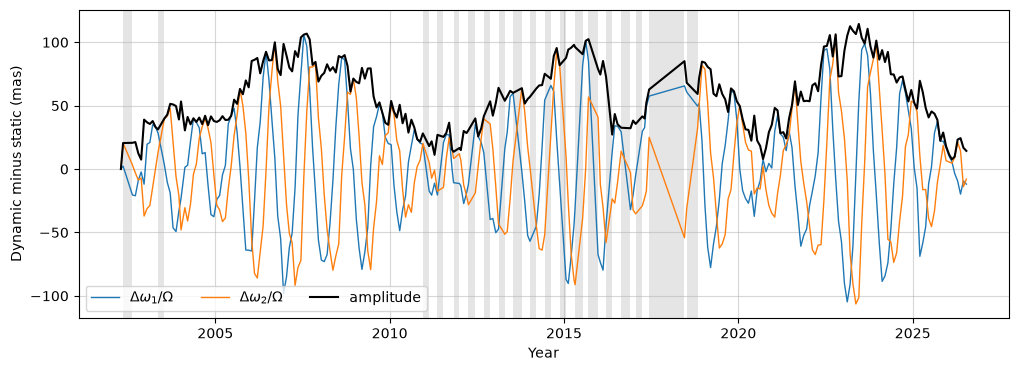

In [6]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(years, difference_mas[:, 0], color="tab:blue", lw=1, label=r"$\Delta\omega_1/\Omega$")
ax.plot(years, difference_mas[:, 1], color="tab:orange", lw=1, label=r"$\Delta\omega_2/\Omega$")
ax.plot(years, np.linalg.norm(difference_mas, axis=1), color="k", lw=1.5, label="amplitude")
for start, end in gaps:
    ax.axvspan(start, end, color="grey", alpha=0.2, lw=0)
ax.set_xlabel("Year")
ax.set_ylabel("Dynamic minus static (mas)")
ax.legend(ncol=3)
ax.grid(True, alpha=0.5)
plt.show()

## 4. The three forcings

The dynamic pole of each forcing, and the trend of the pole (rate and direction, in degrees east of Greenwich) over the whole record.

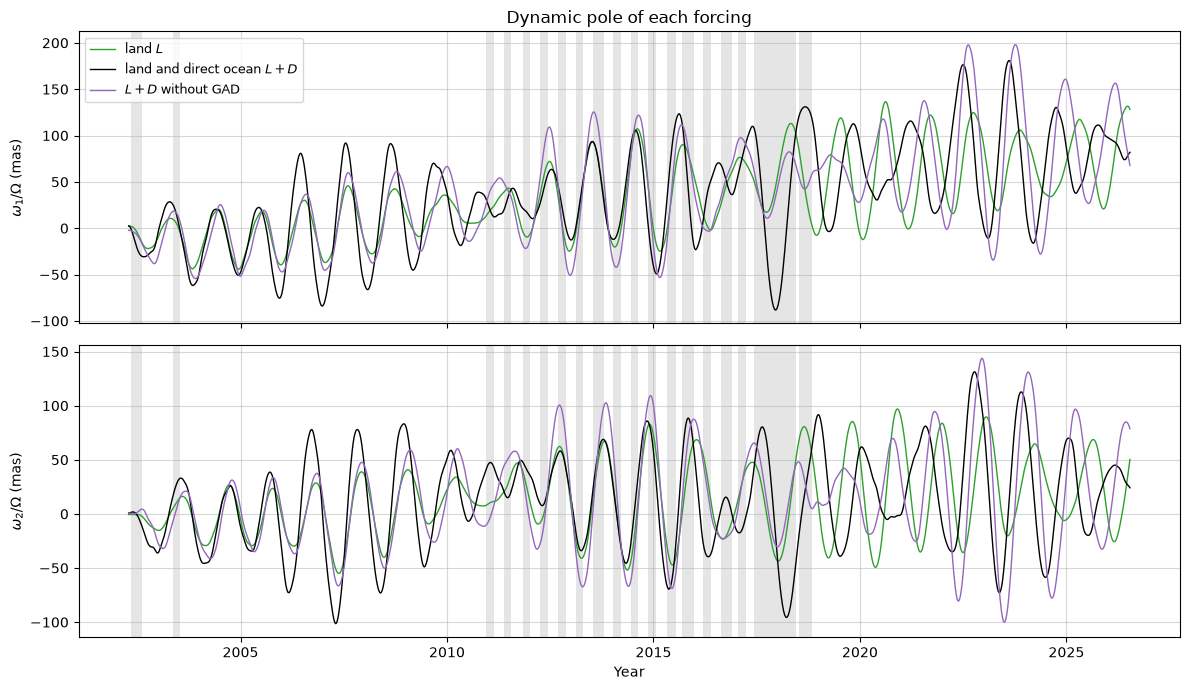

land              dynamic :  4.43 mas/yr towards   19.9 E
land              static  :  4.39 mas/yr towards   21.0 E
land-ocean        dynamic :  4.90 mas/yr towards   18.0 E
land-ocean        static  :  4.87 mas/yr towards   17.6 E
land-ocean-nogad  dynamic :  5.23 mas/yr towards   17.8 E
land-ocean-nogad  static  :  5.06 mas/yr towards   17.3 E


In [7]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for name, colour in zip(gh.FORCINGS, ["tab:green", "k", "tab:purple"]):
    pole = runs[name]["pole_mas"]
    for i, ax in enumerate(axes):
        ax.plot(ph.years_from_days(runs[name]["t_days"]), pole[:, i], color=colour, lw=1, label=forcing_labels[name])
for i, ax in enumerate(axes):
    for start, end in gaps:
        ax.axvspan(start, end, color="grey", alpha=0.2, lw=0)
    ax.set_ylabel(rf"$\omega_{i + 1}/\Omega$ (mas)")
    ax.grid(True, alpha=0.5)
axes[0].legend(fontsize=9)
axes[0].set_title("Dynamic pole of each forcing")
axes[1].set_xlabel("Year")
plt.tight_layout()
plt.show()

# Trend of the pole: rate and the longitude it moves towards
for name in gh.FORCINGS:
    for kind in ["dynamic", "static"]:
        pole = sd.omega_to_mas(runs[name][f"{kind}_omega"], constants)
        trend = [np.polyfit(years, pole[:, i], 1)[0] for i in range(2)]
        print(f"{name:17s} {kind:8s}: {np.hypot(*trend):5.2f} mas/yr towards {np.degrees(np.arctan2(trend[1], trend[0])):6.1f} E")

## 5. Spectrum of the pole

Amplitude spectrum of the complex pole $m=\omega_1+i\omega_2$ (in mas), after removing a straight line, from the monthly values.
Positive frequencies are prograde (the sense of the Chandler wobble), negative ones retrograde. The static pole has an annual
line at $\pm1$ cycle per year; the dynamic pole amplifies the prograde part near the model's free-wobble frequency, found here from a short
free run. The gaps leak some power into side lobes.

model free-wobble period 422.8 d


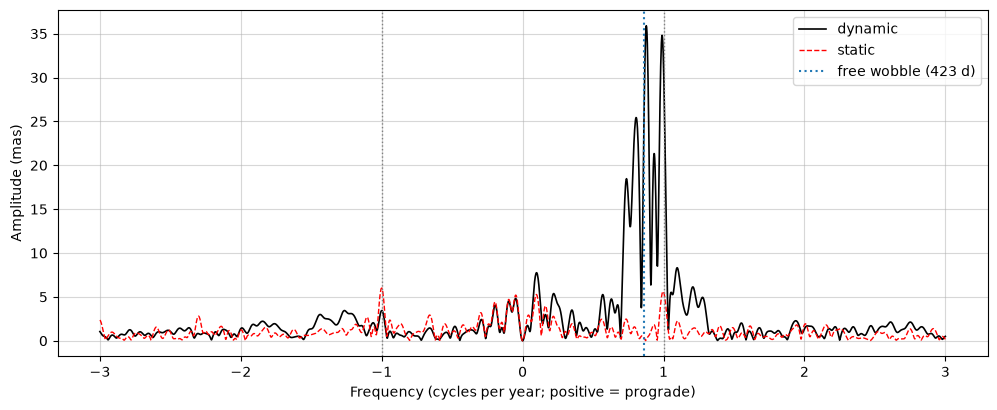

In [8]:
# The model's free-wobble period, from a short free run at lower resolution
state_32 = sd.make_state(32)
constants_32 = sd.rotation_constants(state_32.model)
day_32 = float(sd.days_to_model_time(1.0, constants_32))
no_load = sd.SeparableLoad([(state_32.model.zero_grid(), 0.0)])
rhs = sd.forward_rhs(state_32, constants_32, no_load, quality_factor=float(quality_factor))
t_probe = np.arange(0.0, 1.5 * 365.25 * day_32, 7.0 * day_32)
omega_probe = sd.integrate(rhs, np.array([100.0 / sd.omega_to_mas(1.0, constants_32), 0.0]), t_probe)
chandler_days = eh.wobble_period_days(sd.model_time_to_days(t_probe, constants_32), omega_probe)
print(f"model free-wobble period {chandler_days:.1f} d")

frequencies = np.linspace(-3.0, 3.0, 2401)
dynamic_spectrum = ph.complex_amplitude_spectrum(years, dynamic_mas, frequencies)
static_spectrum = ph.complex_amplitude_spectrum(years, static_mas, frequencies)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(frequencies, dynamic_spectrum, color="k", lw=1.2, label="dynamic")
ax.plot(frequencies, static_spectrum, "r--", lw=1, label="static")
ax.axvline(365.25 / chandler_days, color="tab:blue", ls=":", label=f"free wobble ({chandler_days:.0f} d)")
for f in [-1, 1]:
    ax.axvline(f, color="grey", ls=":", lw=1)
ax.set_xlabel("Frequency (cycles per year; positive = prograde)")
ax.set_ylabel("Amplitude (mas)")
ax.legend()
ax.grid(True, alpha=0.5)
plt.show()

## 6. What drives it: the degree-2, order-1 load

The pole is driven by the degree-2, order-1 coefficients of the total surface load. Shown here for the direct loads: land $L$ and the direct ocean
load $D$ (with GAD). The ocean's response to them (the induced load) is computed inside the solver and is not shown.

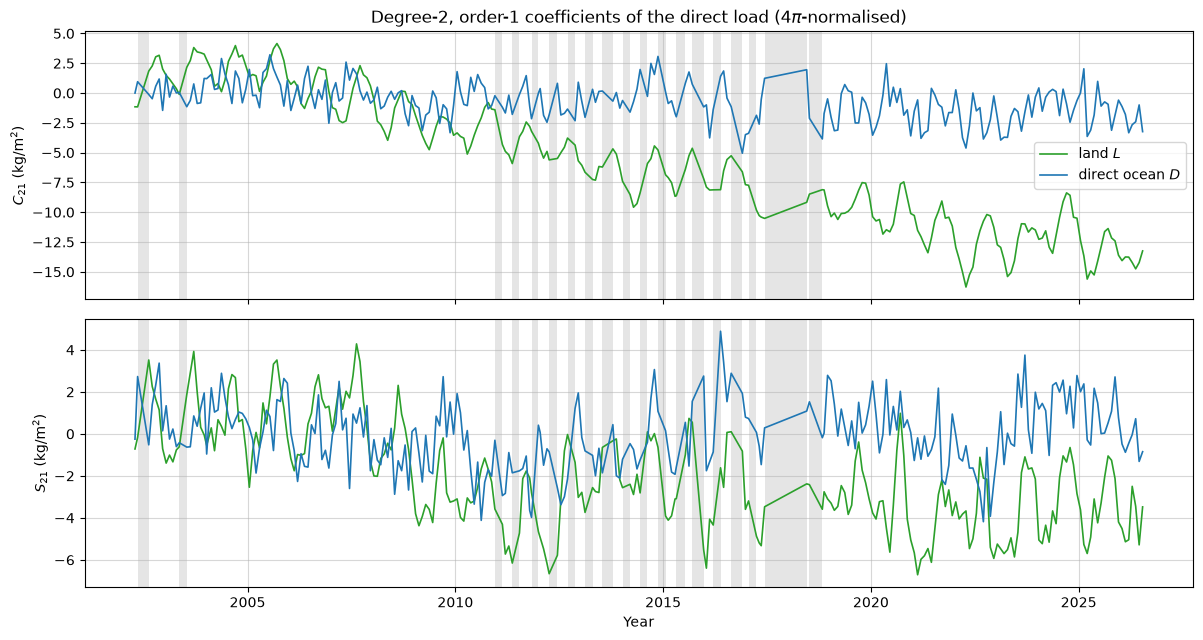

In [9]:
_, _, land_coeffs = gh.direct_load_coefficients("land", lmax)
_, _, land_ocean_coeffs = gh.direct_load_coefficients("land-ocean", lmax)
direct_ocean_coeffs = land_ocean_coeffs - land_coeffs

fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
for i, (ax, name) in enumerate(zip(axes, [r"$C_{21}$", r"$S_{21}$"])):
    ax.plot(years, land_coeffs[:, i, 2, 1], color="tab:green", lw=1.2, label="land $L$")
    ax.plot(years, direct_ocean_coeffs[:, i, 2, 1], color="tab:blue", lw=1.2, label="direct ocean $D$")
    for start, end in gaps:
        ax.axvspan(start, end, color="grey", alpha=0.2, lw=0)
    ax.set_ylabel(f"{name} (kg/m$^2$)")
    ax.grid(True, alpha=0.5)
axes[0].legend()
axes[0].set_title("Degree-2, order-1 coefficients of the direct load (4$\\pi$-normalised)")
axes[1].set_xlabel("Year")
plt.tight_layout()
plt.show()

## 7. Sea level: dynamic against static

Left: the trend of the dynamic sea-level change over the record. Middle: the trend of dynamic minus static, the effect of the lagging
pole on the long-term pattern. Colour limits of the trends ignore the most extreme 1% of values. Right: the root-mean-square of dynamic minus static after removing its trend, mostly the pole tide of the
free wobble.

max |dynamic - static| over the ocean and the record: 5.37 mm


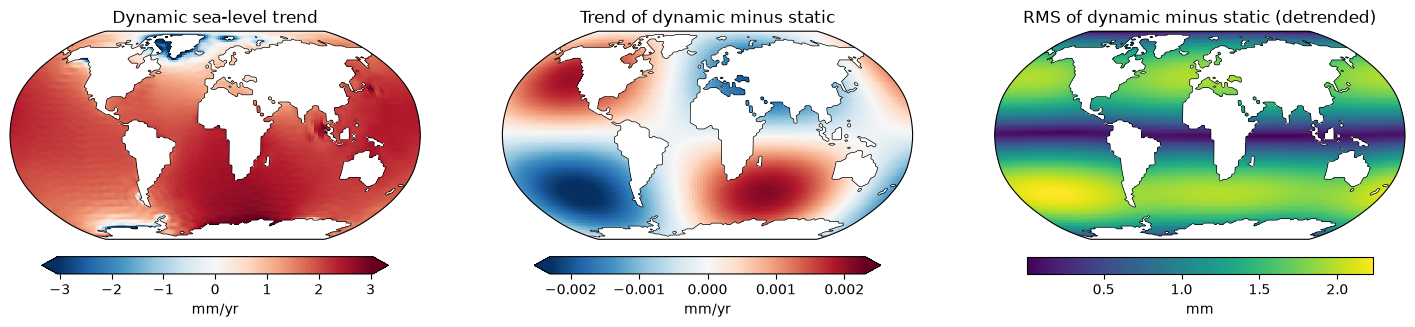

In [10]:
mask = ph.ocean_mask(state)
dynamic_sea_level_mm = ph.fields_from_coefficients(model, run["dynamic_sea_level_coeffs"], scale=1e3, mask=mask)
static_sea_level_mm = ph.fields_from_coefficients(model, run["static_sea_level_coeffs"], scale=1e3, mask=mask)
difference_sea_level_mm = dynamic_sea_level_mm - static_sea_level_mm

maps = [
    (ph.trend_map(years, dynamic_sea_level_mm), "Dynamic sea-level trend", "mm/yr", "RdBu_r"),
    (ph.trend_map(years, difference_sea_level_mm), "Trend of dynamic minus static", "mm/yr", "RdBu_r"),
    (np.sqrt(np.mean(ph.detrend(years, difference_sea_level_mm)**2, axis=0)), "RMS of dynamic minus static (detrended)",
     "mm", "viridis"),
]
print(f"max |dynamic - static| over the ocean and the record: {np.nanmax(np.abs(difference_sea_level_mm)):.2f} mm")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), subplot_kw={"projection": ccrs.Robinson()})
for ax, (field, title, unit, cmap) in zip(axes, maps):
    if cmap == "viridis":
        mesh = ax.pcolormesh(state.lons(), state.lats(), field, transform=ccrs.PlateCarree(), cmap=cmap, shading="auto")
    else:
        limit = ph.robust_limit(field)
        mesh = ax.pcolormesh(state.lons(), state.lats(), field, transform=ccrs.PlateCarree(), cmap=cmap,
                             vmin=-limit, vmax=limit, shading="auto")
    ax.contour(state.lons(), state.lats(), state.ocean_function.data, levels=[0.5], colors="k", linewidths=0.5,
               transform=ccrs.PlateCarree())
    ax.set_global()
    ax.set_title(title)
    fig.colorbar(mesh, ax=ax, orientation="horizontal", pad=0.05, fraction=0.05, label=unit,
                 extend="neither" if cmap == "viridis" else "both")
plt.show()